In [1]:
import pandas as pd
import numpy as np
import os
from sklearn.preprocessing import LabelEncoder, StandardScaler

In [3]:
# import pandas as pd
# import numpy as np
# import os

dataset_path = "../dataset/raw"
file_path = os.path.join(dataset_path, "DrDoS_NTP.csv")

df = pd.read_csv(file_path, low_memory=False)
df.columns = df.columns.str.strip()

print(df.shape)
df.head()

(1217007, 88)


,Unnamed: 0,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,...,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,SimillarHTTP,Inbound,Label
0,0,172.16.0.5-192.168.50.1-60675-80-6,172.16.0.5,60675,192.168.50.1,80,6,2018-12-01 09:17:11.183810,5220876,12,...,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,205.174.165.72/c.php,1,DrDoS_NTP
1,7,172.16.0.5-192.168.50.1-60676-80-6,172.16.0.5,60676,192.168.50.1,80,6,2018-12-01 09:17:11.205636,12644252,5,...,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0,1,DrDoS_NTP
2,12858,192.168.50.7-65.55.163.78-50458-443-6,65.55.163.78,443,192.168.50.7,50458,6,2018-12-01 09:17:12.634569,3,2,...,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0,1,BENIGN
3,10191,192.168.50.7-65.55.163.78-50465-443-6,65.55.163.78,443,192.168.50.7,50465,6,2018-12-01 09:17:13.458370,3,2,...,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0,1,BENIGN
4,239,192.168.50.253-224.0.0.5-0-0-0,192.168.50.253,0,224.0.0.5,0,0,2018-12-01 09:17:13.470913,114329232,52,...,2.466441,15.0,6.0,9527428.0,248706.681286,9950741.0,9092248.0,0,0,BENIGN


In [4]:
# Remove leading/trailing spaces from all string columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Verify labels
print(df["Label"].unique())

['DrDoS_NTP' 'BENIGN']


In [5]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicates
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Duplicate rows: 0
Shape after removing duplicates: (1217007, 88)


In [6]:
# Replace infinite values with NaN
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Check missing values before cleaning
print("Missing values before cleaning:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Remove rows containing missing values
df.dropna(inplace=True)

# Verify
print("\nDataset shape after cleaning:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())

Missing values before cleaning:
Flow Bytes/s      7046
Flow Packets/s    7046
dtype: int64

Dataset shape after cleaning: (1209961, 88)
Remaining missing values: 0


In [7]:
for i, col in enumerate(df.columns):
    print(f"{i:2d}. {col}")

 0. Unnamed: 0
 1. Flow ID
 2. Source IP
 3. Source Port
 4. Destination IP
 5. Destination Port
 6. Protocol
 7. Timestamp
 8. Flow Duration
 9. Total Fwd Packets
10. Total Backward Packets
11. Total Length of Fwd Packets
12. Total Length of Bwd Packets
13. Fwd Packet Length Max
14. Fwd Packet Length Min
15. Fwd Packet Length Mean
16. Fwd Packet Length Std
17. Bwd Packet Length Max
18. Bwd Packet Length Min
19. Bwd Packet Length Mean
20. Bwd Packet Length Std
21. Flow Bytes/s
22. Flow Packets/s
23. Flow IAT Mean
24. Flow IAT Std
25. Flow IAT Max
26. Flow IAT Min
27. Fwd IAT Total
28. Fwd IAT Mean
29. Fwd IAT Std
30. Fwd IAT Max
31. Fwd IAT Min
32. Bwd IAT Total
33. Bwd IAT Mean
34. Bwd IAT Std
35. Bwd IAT Max
36. Bwd IAT Min
37. Fwd PSH Flags
38. Bwd PSH Flags
39. Fwd URG Flags
40. Bwd URG Flags
41. Fwd Header Length
42. Bwd Header Length
43. Fwd Packets/s
44. Bwd Packets/s
45. Min Packet Length
46. Max Packet Length
47. Packet Length Mean
48. Packet Length Std
49. Packet Length Varia

In [8]:
columns_to_drop = [
    "Unnamed: 0",
    "Flow ID",
    "Source IP",
    "Destination IP",
    "Timestamp"
]

df.drop(columns=columns_to_drop, inplace=True)

print(df.shape)

(1209961, 83)


In [9]:
constant_columns = []

for col in df.columns:
    if df[col].nunique() == 1:
        constant_columns.append(col)

print(f"Constant columns ({len(constant_columns)}):")
print(constant_columns)

Constant columns (12):
['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'FIN Flag Count', 'PSH Flag Count', 'ECE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


In [10]:
df.drop(columns=constant_columns, inplace=True)

print(df.shape)


(1209961, 71)


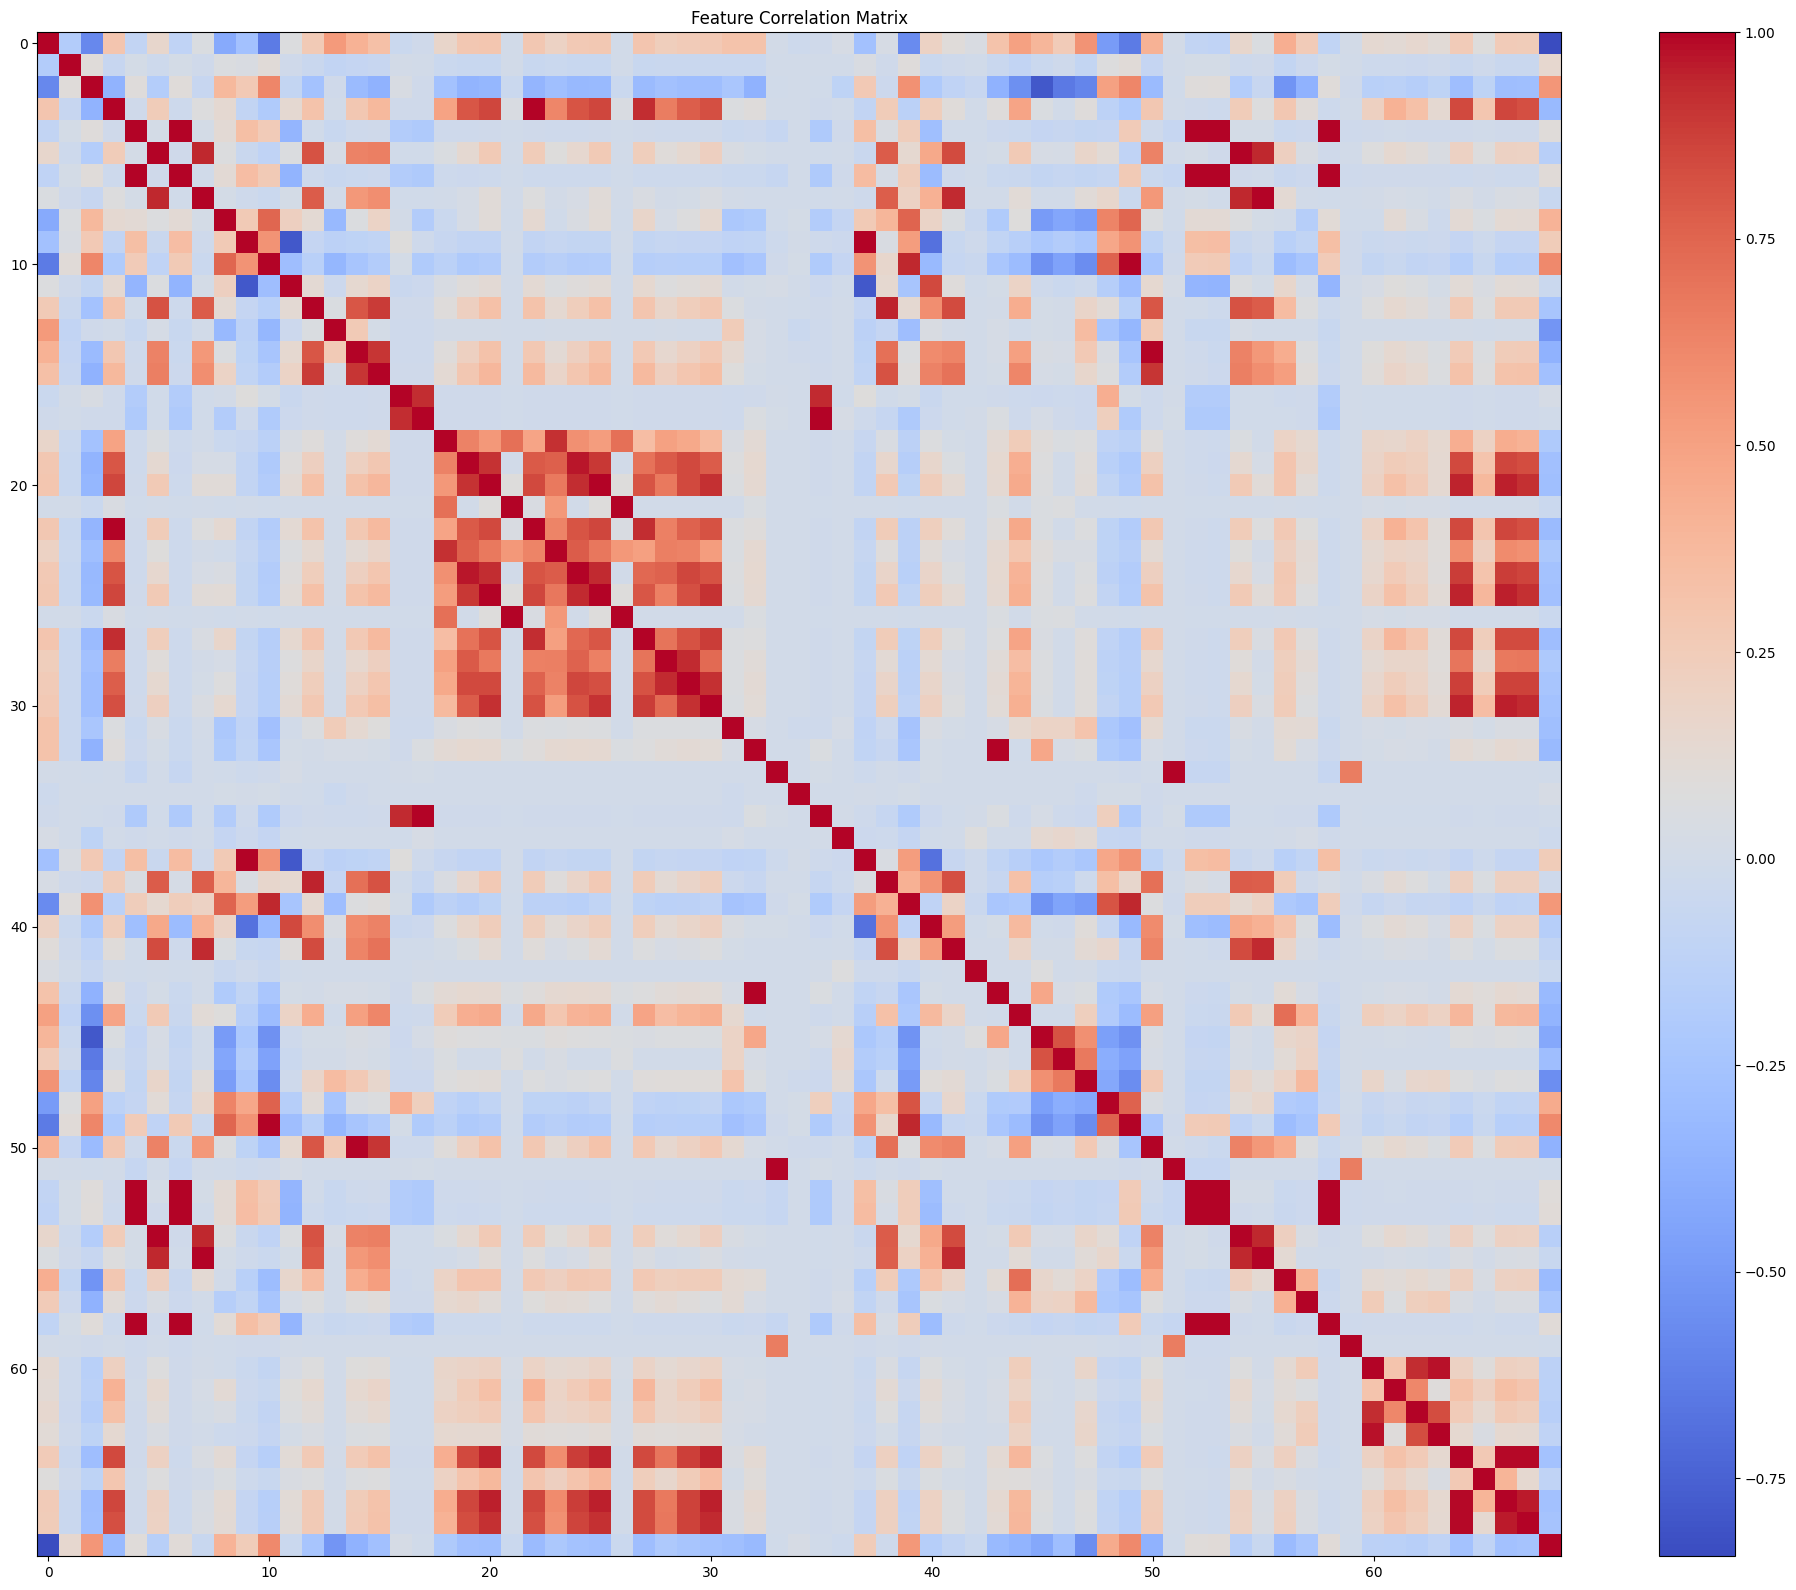

In [12]:
import matplotlib.pyplot as plt

# Exclude the target column
numeric_df = df.select_dtypes(include=[np.number])

# Correlation matrix
corr_matrix = numeric_df.corr()

plt.figure(figsize=(20, 16))
plt.imshow(corr_matrix, cmap="coolwarm", interpolation="nearest")
plt.colorbar()
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [13]:
# Find highly correlated feature pairs
threshold = 0.95

corr_matrix = numeric_df.corr().abs()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr = []

for col in upper.columns:
    for row in upper.index:
        if pd.notna(upper.loc[row, col]) and upper.loc[row, col] > threshold:
            high_corr.append((row, col, upper.loc[row, col]))

print(f"Highly correlated pairs (> {threshold}): {len(high_corr)}")

for pair in high_corr:
    print(pair)

Highly correlated pairs (> 0.95): 29
('Total Fwd Packets', 'Total Length of Fwd Packets', np.float64(0.9992965815827005))
('Flow Duration', 'Fwd IAT Total', np.float64(0.997638077419611))
('Flow IAT Std', 'Fwd IAT Std', np.float64(0.9703290398038956))
('Flow IAT Max', 'Fwd IAT Max', np.float64(0.9931585369257206))
('Flow IAT Min', 'Fwd IAT Min', np.float64(0.9981047138262346))
('Flow Packets/s', 'Fwd Packets/s', np.float64(0.9997912401677211))
('Fwd Packet Length Min', 'Min Packet Length', np.float64(0.9996487945766059))
('Fwd PSH Flags', 'RST Flag Count', np.float64(1.0))
('Fwd Packet Length Mean', 'Avg Fwd Segment Size', np.float64(1.0))
('Bwd Packet Length Mean', 'Avg Bwd Segment Size', np.float64(1.0))
('Fwd Header Length', 'Fwd Header Length.1', np.float64(1.0))
('Total Fwd Packets', 'Subflow Fwd Packets', np.float64(1.0))
('Total Length of Fwd Packets', 'Subflow Fwd Packets', np.float64(0.9992965815827005))
('Total Fwd Packets', 'Subflow Fwd Bytes', np.float64(0.9992965815827005)

In [14]:
redundant_columns = [
    "Fwd Header Length.1",
    "Avg Fwd Segment Size",
    "Avg Bwd Segment Size",
    "Subflow Fwd Packets",
    "Subflow Fwd Bytes",
    "Subflow Bwd Packets",
    "Subflow Bwd Bytes"
]

df.drop(columns=redundant_columns, inplace=True)

print(df.shape)

(1209961, 64)


In [15]:
print(df["SimillarHTTP"].dtype)
print(df["SimillarHTTP"].nunique())
print(df["SimillarHTTP"].value_counts().head(20))

object
300
SimillarHTTP
0                                                                                                                            1208801
205.174.165.72/c.php                                                                                                             461
ocsp.pki.goog/GTSGIAG3                                                                                                            68
ocsp.digicert.com/                                                                                                                67
205.174.165.72null                                                                                                                18
drmokhberi.ca/favicon.ico                                                                                                         13
en.drshno.com/                                                                                                                    13
205.174.165.72/c.php?ip=10.148.118.37        

In [16]:
df.drop(columns=["SimillarHTTP"], inplace=True)

print(df.shape)

(1209961, 63)


In [17]:
print(df["Label"].value_counts())

Label
DrDoS_NTP    1195690
BENIGN         14271
Name: count, dtype: int64


In [18]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

df["Label"] = label_encoder.fit_transform(df["Label"])

print(label_encoder.classes_)
print(df["Label"].value_counts())

['BENIGN' 'DrDoS_NTP']
Label
1    1195690
0      14271
Name: count, dtype: int64
